In [3]:
import pandas as pd

df = pd.read_csv("zomato.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (9551, 21)

Column names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [4]:
print("Online delivery values:")
print(df["Has Online delivery"].value_counts(dropna=False))

print("\nRating column:")
print(df["Aggregate rating"].head())

Online delivery values:
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64

Rating column:
0    4.8
1    4.5
2    4.4
3    4.9
4    4.8
Name: Aggregate rating, dtype: float64


In [5]:
# Calculate online delivery percentages

delivery_counts = df["Has Online delivery"].value_counts()

total_restaurants = len(df)
delivery_yes = delivery_counts.get("Yes", 0)
delivery_no = delivery_counts.get("No", 0)

yes_percentage = (delivery_yes / total_restaurants) * 100
no_percentage = (delivery_no / total_restaurants) * 100

print("=" * 40)
print("COGNIFYZ - LEVEL 1, TASK 4")
print("ONLINE DELIVERY ANALYSIS")
print("=" * 40)

print(f"Total restaurants: {total_restaurants}")
print(f"Online delivery available: {delivery_yes}")
print(f"Online delivery unavailable: {delivery_no}")
print(f"Delivery available percentage: {yes_percentage:.2f}%")
print(f"Delivery unavailable percentage: {no_percentage:.2f}%")
print("=" * 40)

COGNIFYZ - LEVEL 1, TASK 4
ONLINE DELIVERY ANALYSIS
Total restaurants: 9551
Online delivery available: 2451
Online delivery unavailable: 7100
Delivery available percentage: 25.66%
Delivery unavailable percentage: 74.34%


In [6]:
# Compare average ratings

average_ratings = df.groupby("Has Online delivery")["Aggregate rating"].mean()

print("=" * 40)
print("AVERAGE RATING COMPARISON")
print("=" * 40)

print(f"Without online delivery: {average_ratings['No']:.2f}")
print(f"With online delivery:    {average_ratings['Yes']:.2f}")

print("=" * 40)

AVERAGE RATING COMPARISON
Without online delivery: 2.47
With online delivery:    3.25


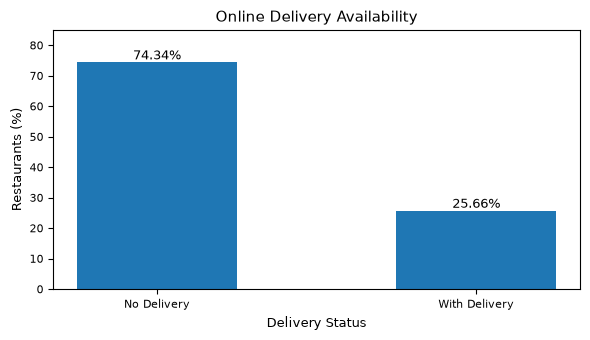

In [9]:
import matplotlib.pyplot as plt

delivery_counts = df["Has Online delivery"].value_counts().reindex(["No", "Yes"])
percentages = (delivery_counts / len(df)) * 100

plt.figure(figsize=(6, 3.5))

bars = plt.bar(
    ["No Delivery", "With Delivery"],
    percentages.values,
    width=0.5
)

plt.title("Online Delivery Availability", fontsize=11)
plt.xlabel("Delivery Status", fontsize=9)
plt.ylabel("Restaurants (%)", fontsize=9)
plt.ylim(0, 85)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("Online_Delivery_Percentage.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
summary = pd.DataFrame({
    "Delivery Status": ["No", "Yes"],
    "Restaurant Count": [
        delivery_counts["No"],
        delivery_counts["Yes"]
    ],
    "Percentage (%)": [
        percentages["No"],
        percentages["Yes"]
    ],
    "Average Rating": [
        average_ratings["No"],
        average_ratings["Yes"]
    ]
})

summary.to_csv("Online_Delivery_Results.csv", index=False)

print("Results saved successfully!")
display(summary)

Results saved successfully!


,Delivery Status,Restaurant Count,Percentage (%),Average Rating
0,No,7100,74.337766,2.465296
1,Yes,2451,25.662234,3.248837


In [11]:
print("=" * 50)
print("FINAL INSIGHTS AND CONCLUSION")
print("=" * 50)

print("1. Total restaurants analyzed:", len(df))
print(f"2. Online delivery is available at {yes_percentage:.2f}% of restaurants.")
print(f"3. Online delivery is unavailable at {no_percentage:.2f}% of restaurants.")
print(f"4. Average rating with delivery: {average_ratings['Yes']:.2f}")
print(f"5. Average rating without delivery: {average_ratings['No']:.2f}")

rating_difference = average_ratings["Yes"] - average_ratings["No"]

print(f"6. Rating difference: {rating_difference:.2f} points.")

print("\nConclusion:")
print("Restaurants offering online delivery have a higher average rating")
print("in this dataset. This is an association, not proof that delivery")
print("causes higher ratings.")
print("=" * 50)

FINAL INSIGHTS AND CONCLUSION
1. Total restaurants analyzed: 9551
2. Online delivery is available at 25.66% of restaurants.
3. Online delivery is unavailable at 74.34% of restaurants.
4. Average rating with delivery: 3.25
5. Average rating without delivery: 2.47
6. Rating difference: 0.78 points.

Conclusion:
Restaurants offering online delivery have a higher average rating
in this dataset. This is an association, not proof that delivery
causes higher ratings.
